In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import DensityMatrix, entropy
import bosonic_qiskit as c2qa

# ------------------------------- USER PARAMETERS ------------------------------------
N_SITES   = 8        
                       
CUTOFF    = 2          # Fock truncation per qumode (photon numbers 0..CUTOFF-1)
USE_MPS   = True       # matrix_product_state backend 

wc        = 1.0        # cavity frequency
wa        = 1.0        # atom frequency
DETUNING  = wc - wa    
g         = 0.35        # Jaynes-Cummings coupling
J         = 0.15        # inter-site photon hopping

DT        = 0.05       # Trotter step size
N_STEPS   = 5000         # -> T_max = N_STEPS * DT

INIT_SITE = N_SITES // 2   
ENT_SITE  = INIT_SITE       
# --------------------------------------------------------------------------------------

m = int(np.ceil(np.log2(CUTOFF)))          # qubits per qumode
total_qubits = N_SITES * (m + 1)
print(f"[info] N_SITES={N_SITES}, CUTOFF={CUTOFF} -> {m} qubit(s)/qumode, "
      f"{total_qubits} total qubits")

qmr = c2qa.QumodeRegister(num_qumodes=N_SITES, num_qubits_per_qumode=m)
qr  = qiskit.QuantumRegister(N_SITES, name="atom")
circuit = c2qa.CVCircuit(qmr, qr)

# ------------------------------- initial state ---------------------------------------

for i in range(N_SITES):
    circuit.cv_initialize(1 if i == INIT_SITE else 0, qmr[i])
    circuit.x(qr[i])             


# ------------------------------- qubit-index bookkeeping ------------------------------
def qumode_qubits(site):
    return list(range(site * m, site * m + m))

def atom_qubit(site):
    return N_SITES * m + site

def site_block(site):
    return qumode_qubits(site) + [atom_qubit(site)]

# ------------------------------- local operators (dense, tiny) ------------------------
def number_op_mode():
    dim = 2 ** m
    return np.diag([min(k, CUTOFF - 1) for k in range(dim)]).astype(complex)


def number_op_atom():
    return np.diag([1.0, 0.0]).astype(complex)   # <-- was [0.0, 1.0]

N_MODE_OP = number_op_mode()
N_ATOM_OP = number_op_atom()

I_MODE = np.eye(2 ** m)
I_ATOM = np.eye(2)
N_SITE_OP = np.kron(N_ATOM_OP, I_MODE) + np.kron(I_ATOM, N_MODE_OP)

# N_SITE_OP = np.kron(N_MODE_OP, np.eye(2)) + np.kron(I_MODE, N_ATOM_OP)

# ------------------------------- build circuit + save instructions --------------------
def append_trotter_step(circ):
    # on-site Jaynes-Cummings coupling g(a^dag sigma- + a sigma+)
    for i in range(N_SITES):
        circ.cv_jc(g * DT, 0.0, qmr[i], qr[i])
        circ.barrier()

        

    
    if abs(DETUNING) > 1e-12:
        for i in range(N_SITES):
            circ.cv_r(wc * DT, qmr[i])
            circ.rz(wa * DT, qr[i])
            circ.barrier()

    #  nearest-neighbour photon hopping (beamsplitter realizes a_i^dag a_j + h.c.)
    for i in range(N_SITES - 1):
        circ.cv_bs(-J * DT, qmr[i], qmr[i + 1])
        circ.barrier()
        
#circuit.draw("mpl", style={"backgroundcolor": "#eeeeee", "dpi": 150})



[info] N_SITES=8, CUTOFF=2 -> 1 qubit(s)/qumode, 16 total qubits


In [2]:
labels_occ = []   # (t_index, site) -> label
labels_ent = []   # t_index -> label

for site in range(N_SITES):
    lbl = f"occ_s{site}_t0"
    circuit.save_density_matrix(qubits=site_block(site), label=lbl)
    labels_occ.append((0, site, lbl))
lbl = "ent_t0"
circuit.save_density_matrix(qubits=site_block(ENT_SITE), label=lbl)
labels_ent.append((0, lbl))

for t in range(1, N_STEPS + 1):
    append_trotter_step(circuit)
    for site in range(N_SITES):
        lbl = f"occ_s{site}_t{t}"
        circuit.save_density_matrix(qubits=site_block(site), label=lbl)
        labels_occ.append((t, site, lbl))
    lbl = f"ent_t{t}"
    circuit.save_density_matrix(qubits=site_block(ENT_SITE), label=lbl)
    labels_ent.append((t, lbl))

#circuit.draw("mpl",scale=0.7,fold=100, style={"backgroundcolor": "#eeeeee", "dpi": 150})


In [ ]:
# ------------------------------- run ---------------------------------------------------
backend = AerSimulator(method="matrix_product_state" if USE_MPS else "statevector")
tcirc = transpile(circuit, backend)
result = backend.run(tcirc).result()
print(result.results[0].metadata.get("method"))
data = result.data(0)
#save data to file for later analysis
np.savez("jch_disorder_11_jch_model_data.npz", **data)

# ------------------------------- post-process -----------------------------------------
occupancy = np.zeros((N_SITES, N_STEPS + 1))
for (t, site, lbl) in labels_occ:
    rho = np.asarray(data[lbl])
    occupancy[site, t] = np.real(np.trace(rho @ N_SITE_OP))

ent_S = np.zeros(N_STEPS + 1)
for (t, lbl) in labels_ent:
    rho = np.asarray(data[lbl])
    dm = DensityMatrix(rho)
    ent_S[t] = entropy(dm, base=2)  # von Neumann entropy of ENT_SITE vs rest of chain

times = np.arange(N_STEPS + 1) * DT

In [3]:
data = np.load("jch_disorder_11_jch_model_data.npz")
trotter_occupancy = np.zeros((N_SITES, N_STEPS+1))
for (t, site, lbl) in labels_occ:
    rho = np.asarray(data[lbl])
    trotter_occupancy[site, t] = np.real(np.trace(rho @ N_SITE_OP))
print("total occupancy min/max:",
      trotter_occupancy.sum(axis=0).min(), trotter_occupancy.sum(axis=0).max())


total occupancy min/max: 0.9999999999250426 1.0000000000718376


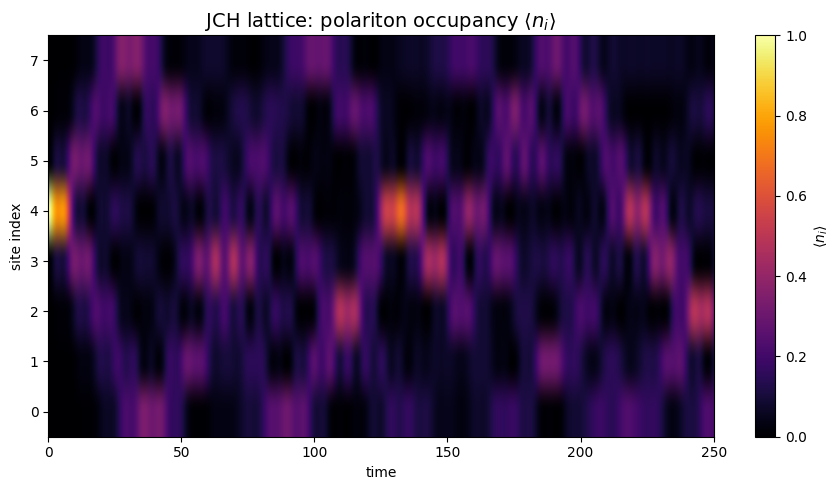

In [ ]:
fig1, ax1 = plt.subplots(figsize=(9, 5))
im = ax1.imshow(occupancy, aspect="auto", origin="lower",
                 extent=[times[0], times[-1], -0.5, N_SITES - 0.5], cmap="inferno")
ax1.set_xlabel("time")
ax1.set_ylabel("site index")
ax1.set_title("JCH lattice: polariton occupancy $\\langle n_i \\rangle$", fontsize=14)
fig1.colorbar(im, ax=ax1, label=r"$\langle n_i \rangle$")
fig1.tight_layout()
fig1.savefig(f"jch_occupancy_heatmap{N_SITES}.pdf", dpi=150)
plt.show()
#print the time range for the 2nd and 3rd maxima of the 4th site occupancy
site_4_occupancy = occupancy[:, 3]
maxima_indices = argrelextrema(site_4_occupancy, np.greater)
print(f"Time range for 2nd maximum: {times[maxima_indices[0][1]]} to {times[maxima_indices[0][2]]}")
print(f"Time range for 3rd maximum: {times[maxima_indices[0][2]]} to {times[maxima_indices[0][3]]}")


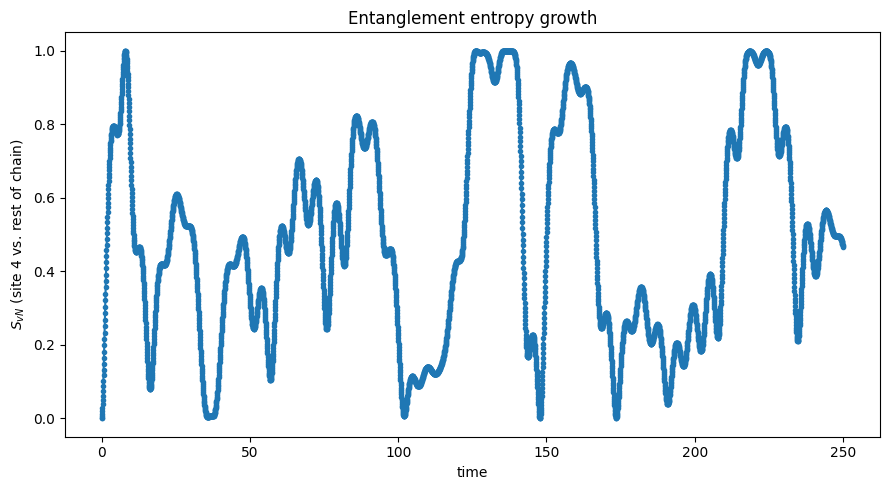

In [8]:
# ------------------------------- plot2 --------------------------------------------------

fig2, ax2 = plt.subplots(figsize=(9,5))
ax2.plot(times, ent_S, marker="o", ms=3)
ax2.set_xlabel("time")
ax2.set_ylabel(f"$S_{{vN}}$ (site {ENT_SITE} vs. rest of chain)")
ax2.set_title("Entanglement entropy growth")
fig2.tight_layout()
fig2.savefig(f"jch_entanglement_entropy{N_SITES}.pdf", dpi=150)

plt.show()



total occupancy min/max: 0.9999999999999966 1.0000000000000018


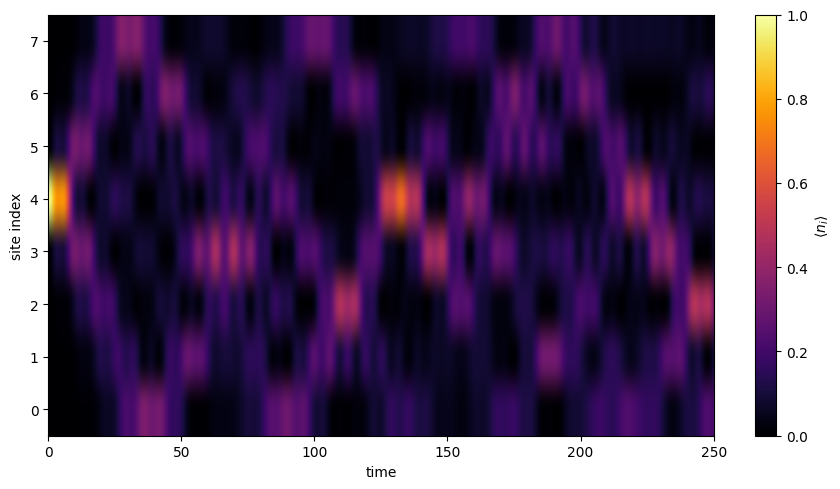

In [ ]:
"""
Exact (non-Trotterized) reference solution for the Jaynes-Cummings-Hubbard
lattice.

"""

import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt

# -------------------  parameters -------------------------
N_SITES   = 8
wc        = 1.0
wa        = 1.0
g         = 0.35
J         = 0.15
INIT_SITE = N_SITES // 2
T_max     = 250
N_TPOINTS = 500
# ----------------------------------------------------------

# basis layout: [mode_0 .. mode_{N-1}, atom_0 .. atom_{N-1}]
dim = 2 * N_SITES
def mode_idx(i): return i
def atom_idx(i): return N_SITES + i

H = np.zeros((dim, dim))
for i in range(N_SITES):
    H[mode_idx(i), mode_idx(i)] = wc      # cavity on-site energy
    H[atom_idx(i), atom_idx(i)] = wa      # atom on-site energy
    H[mode_idx(i), atom_idx(i)] = g       # Jaynes-Cummings coupling
    H[atom_idx(i), mode_idx(i)] = g
for i in range(N_SITES - 1):
    H[mode_idx(i),   mode_idx(i + 1)] = -J   # nearest-neighbour hopping
    H[mode_idx(i + 1), mode_idx(i)]   = -J

# initial state: single photon at INIT_SITE, everything else vacuum/ground
psi0 = np.zeros(dim, dtype=complex)
psi0[mode_idx(INIT_SITE)] = 1.0

# diagonalize once; evolution at any t is then just a phase rotation
evals, evecs = la.eigh(H)
c0 = evecs.conj().T @ psi0

# times = np.linspace(0, T_max, N_TPOINTS)
# occupancy = np.zeros((N_SITES, len(times)+1))
times = np.linspace(0, T_max, trotter_occupancy.shape[1])
occupancy = np.zeros((N_SITES, len(times)))
for ti, t in enumerate(times):
    psit = evecs @ (np.exp(-1j * evals * t) * c0)
    for i in range(N_SITES):
        occupancy[i, ti] = abs(psit[mode_idx(i)]) ** 2 + abs(psit[atom_idx(i)]) ** 2

print("total occupancy min/max:",
      occupancy.sum(axis=0).min(), occupancy.sum(axis=0).max())

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(occupancy, aspect="auto", origin="lower",
                extent=[times[0], times[-1], -0.5, N_SITES - 0.5],
                cmap="inferno", vmin=0, vmax=1)
ax.set_xlabel("time")
ax.set_ylabel("site index")
#ax.set_title("Exact diagonalization solution: polariton occupancy $\\langle n_i \\rangle$", fontsize=14)
fig.colorbar(im, ax=ax, label=r"$\langle n_i \rangle$")
fig.tight_layout()
plt.show()
save_path = f"jch_exact_occupancy_heatmap{N_SITES}.pdf"
#fig.savefig(save_path, bbox_inches='tight')

total occupancy min/max: 0.9999999999250426 1.0000000000718376


occupancy difference min/max: 9.75789437226681e-32 0.0069846980309736795


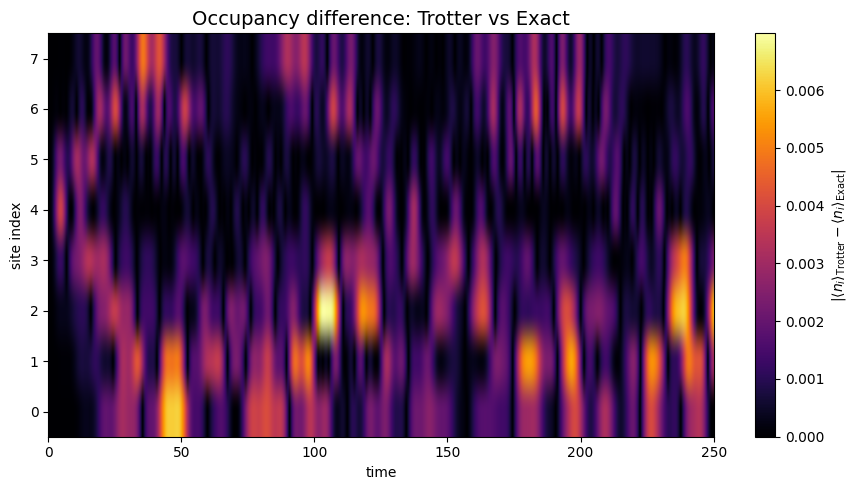

In [5]:
#comparing two heatmaps (Trotter vs exact) 
#load the saved data from the Trotter simulation
data = np.load("jch_disorder_11_jch_model_data.npz")
trotter_occupancy = np.zeros((N_SITES, N_STEPS + 1))
for (t, site, lbl) in labels_occ:
    rho = np.asarray(data[lbl])
    trotter_occupancy[site, t] = np.real(np.trace(rho @ N_SITE_OP))

#finding the difference between the two occupancy matrices
occupancy_diff = np.abs(trotter_occupancy - occupancy)
print("occupancy difference min/max:", occupancy_diff.min(), occupancy_diff.max())

#plotting the difference heatmap
fig_diff, ax_diff = plt.subplots(figsize=(9, 5))
im_diff = ax_diff.imshow(occupancy_diff, aspect="auto", origin="lower",
                         extent=[times[0], times[-1], -0.5, N_SITES - 0.5],
                         cmap="inferno")
ax_diff.set_title("Occupancy difference: Trotter vs Exact", fontsize=14)
ax_diff.set_xlabel("time")
ax_diff.set_ylabel("site index")
save_path = "jch_occupancy_difference.pdf"
fig_diff.colorbar(im_diff, ax=ax_diff, label=r"$|\langle n_i \rangle_{\text{Trotter}} - \langle n_i \rangle_{\text{Exact}}|$")
fig_diff.tight_layout()
#fig_diff.savefig(save_path, bbox_inches='tight')

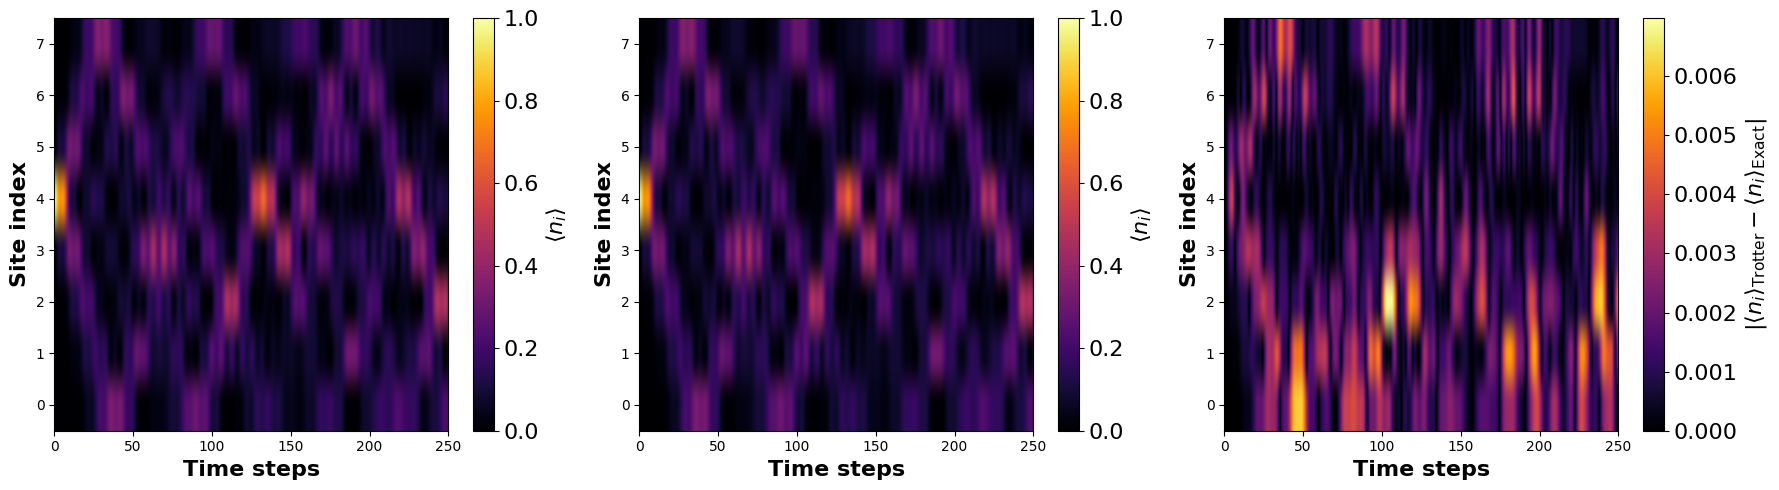

In [13]:
#plotting 2 heatmaps and the difference heatmap side by side
fig_combined, axs = plt.subplots(1, 3, figsize=(18, 5))
im1 = axs[0].imshow(trotter_occupancy, aspect="auto", origin="lower",
                    extent=[times[0], times[-1], -0.5, N_SITES - 0.5], cmap="inferno", vmin=0, vmax=1)
#axs[0].set_title("Trotter Occupancy", fontsize=14)
im2 = axs[1].imshow(occupancy, aspect="auto", origin="lower",
                    extent=[times[0], times[-1], -0.5, N_SITES - 0.5], cmap="inferno", vmin=0, vmax=1)
#axs[1].set_title("Exact Occupancy", fontsize=14)
im3 = axs[2].imshow(occupancy_diff, aspect="auto", origin="lower",
                    extent=[times[0], times[-1], -0.5, N_SITES - 0.5], cmap="inferno")
#axs[2].set_title("Difference", fontsize=14)
for ax in axs:
    ax.set_xlabel("Time steps", fontsize=16, fontweight="bold")
    ax.set_ylabel("Site index", fontsize=16, fontweight="bold")

cbar1 = fig_combined.colorbar(im1, ax=axs[0], label=r"$\langle n_i \rangle$")
cbar2 = fig_combined.colorbar(im2, ax=axs[1], label=r"$\langle n_i \rangle$")
cbar3 = fig_combined.colorbar(
    im3,
    ax=axs[2],
    label=r"$|\langle n_i \rangle_{\text{Trotter}} - \langle n_i \rangle_{\text{Exact}}|$"
)


#increase fontsize of colorbar labels
for colorbar in (cbar1, cbar2, cbar3):
    colorbar.ax.tick_params(labelsize=16)

#increase fontsize of colorbar labels
for colorbar in (cbar1, cbar2, cbar3):
    colorbar.ax.yaxis.label.set_fontsize(16)
    colorbar.ax.yaxis.label.set_fontweight("bold")


fig_combined.tight_layout()
save_path_combined = "jch_occupancy_comparison.pdf"
fig_combined.savefig(save_path_combined, bbox_inches='tight')

Mean Squared Error (MSE): 3.3336760415133856e-06


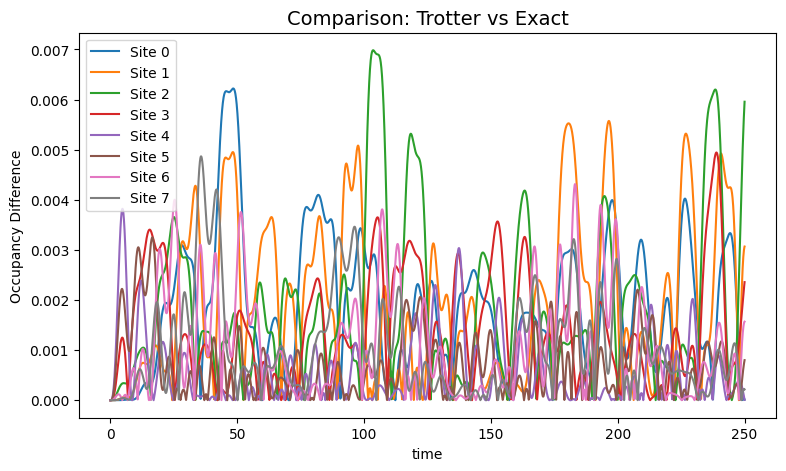

In [18]:
#error analysis: compute the mean squared error (MSE) between the two occupancy matrices
mse = np.mean(occupancy_diff ** 2)
print("Mean Squared Error (MSE):", mse)

#error comparision plot for each site for both Trotter and exact solutions
fig, ax = plt.subplots(figsize=(9, 5))
for site in range(N_SITES):
    ax.plot(times, occupancy_diff[site, :], label=f"Site {site}")
ax.set_xlabel("time")
ax.set_ylabel("Occupancy Difference")
ax.set_title("Comparison: Trotter vs Exact", fontsize=14)
ax.legend()
plt.show()


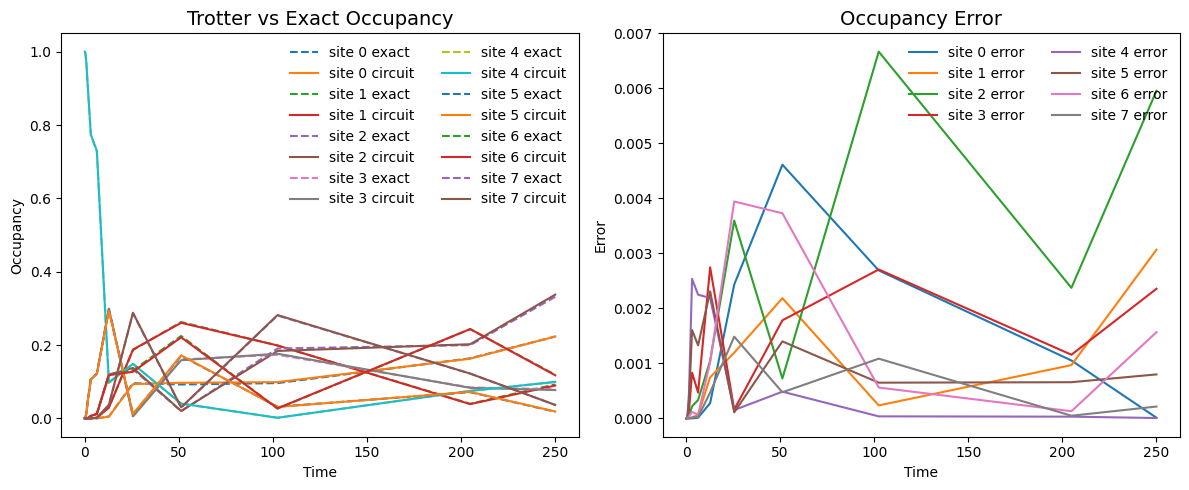

In [8]:
# Use the explicit checkpoint indices and convert them to the corresponding
# physical time values on the full simulation grid.

CHECKPOINTS = np.array([0,2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048,4096,5000], dtype=int)
checkpoint_times = times[CHECKPOINTS]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for site in range(N_SITES):
    axes[0].plot(checkpoint_times, occupancy[site, CHECKPOINTS], label=f"site {site} exact", ls="--")
    axes[0].plot(checkpoint_times, trotter_occupancy[site, CHECKPOINTS], label=f"site {site} circuit", ls="-")
    axes[1].plot(checkpoint_times, occupancy_diff[site, CHECKPOINTS], label=f"site {site} error", ls="-")

axes[0].set_xlabel("Time")
axes[0].set_ylabel("Occupancy")
axes[0].set_title("Trotter vs Exact Occupancy", fontsize=14)
axes[0].legend()
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Error")
axes[1].set_title("Occupancy Error", fontsize=14)
axes[1].legend()

axes[0].legend(ncol=2, frameon=False)
axes[1].legend(ncol=2, frameon=False)

#making 


plt.tight_layout()
plt.show()
# save_path = "jch_occupancy_comparison_with_error.pdf"
# fig.savefig(save_path, bbox_inches='tight')



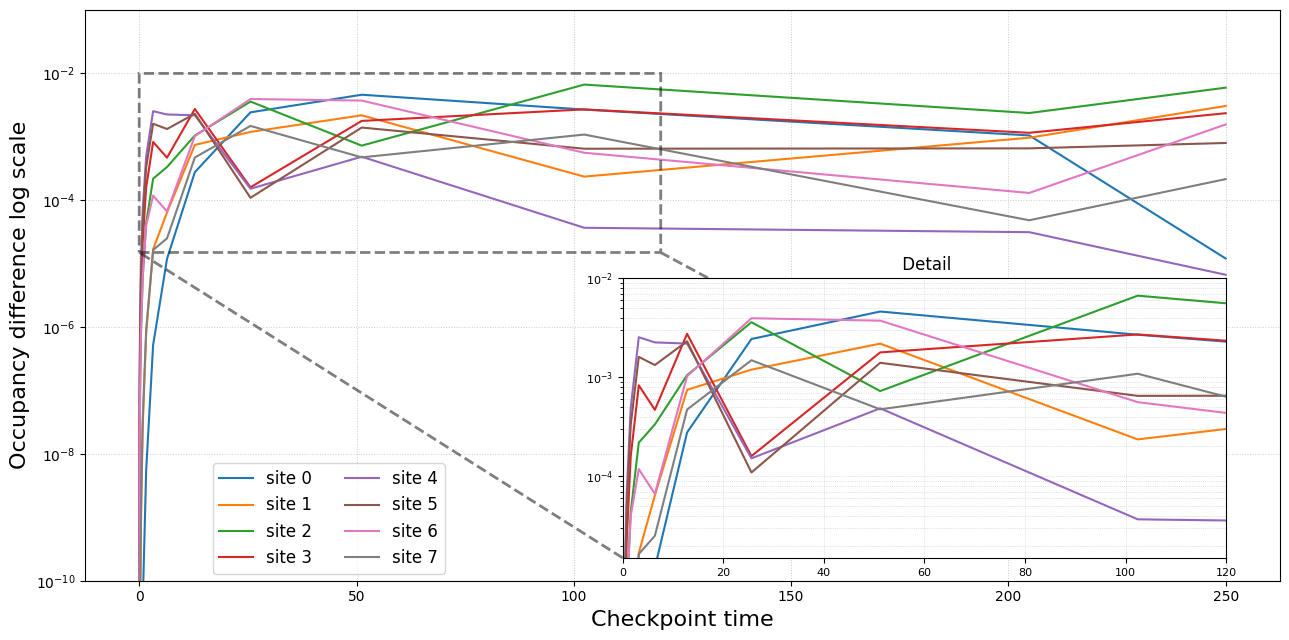

In [60]:
CHECKPOINTS = np.array([0,2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048,4096,5000], dtype=int)
checkpoint_times = times[CHECKPOINTS]

# Single combined plot with distinct line styles and a zoomed plateau inset.
fig, ax = plt.subplots(figsize=(13, 6.5))

# markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
# line_styles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (7, 2)), (0, (1, 1))]
plot_errors = np.maximum(occupancy_diff[:, CHECKPOINTS], 1e-12)

for site in range(N_SITES):
    ax.plot( checkpoint_times, plot_errors[site], label=f"site {site}")

ax.set_xlabel("Checkpoint time", fontsize=16)
ax.set_ylabel("Occupancy difference log scale", fontsize=16)
#ax.set_title("Occupancy Difference (Trotter vs Exact) at Checkpoints", fontsize=15)
ax.set_yscale("log")
ax.set_ylim(1e-10, 1e-1)
ax.grid(True, which="both", linestyle=":", linewidth=0.7, alpha=0.65)
ax.legend(ncol=2, frameon=True, loc="upper left", bbox_to_anchor=(0.10, 0.22), fontsize=12)

# Magnify the region where the curves form a plateau.
inset = ax.inset_axes([0.45, 0.04, 0.505, 0.49])  # [x0, y0, width, height] in axes fraction
for site in range(N_SITES):
    inset.plot(
        checkpoint_times,
        plot_errors[site]
    )

# making zoom connecting lines
ax.indicate_inset_zoom(inset, edgecolor="black", alpha=0.5, linewidth=2.0, linestyle="--")

#inset.set_xlim(16, checkpoint_times[-1])
inset.set_xlim(0, 120)
inset.set_ylim(1.5e-5, 1e-2)
inset.set_yscale("log")
inset.set_title(" Detail", fontsize=12)
inset.grid(True, which="both", linestyle=":", linewidth=0.5, alpha=0.65)
inset.tick_params(labelsize=8)

#smoothing the curve in inset


fig.tight_layout()
save_path = "jch_occupancy_difference_logscale_with_inset.pdf"
fig.savefig(save_path, bbox_inches='tight')
plt.show()

In [31]:
from qiskit.quantum_info import DensityMatrix, entropy, partial_trace, concurrence

data = np.load("jch_disorder_11_jch_model_data.npz")   # if starting a fresh session
time_axis = DT * np.arange(N_STEPS + 1)

# ---- generic Rényi entropy (order alpha != 1); alpha->1 recovers von Neumann ----
def renyi_entropy(rho, alpha=2, base=2):
    evals = np.linalg.eigvalsh(np.asarray(rho))
    evals = np.clip(evals, 0, None)
    evals = evals[evals > 1e-12]
    tr_rho_alpha = np.sum(evals ** alpha)
    return np.log(tr_rho_alpha) / ((1.0 - alpha) * np.log(base))

RENYI_ORDERS = [0.5, 2, 3]   # add/remove orders as you like

# ---- storage ----
S_vn   = np.zeros((N_STEPS + 1, N_SITES))              # local (site-block) von Neumann entropy
S_ren  = {a: np.zeros((N_STEPS + 1, N_SITES)) for a in RENYI_ORDERS}
S_atom = np.zeros((N_STEPS + 1, N_SITES))               # atom-only entropy within the site block
S_mode = np.zeros((N_STEPS + 1, N_SITES))               # mode-only entropy within the site block
I_am   = np.zeros((N_STEPS + 1, N_SITES))               # atom-mode mutual information
C_site = np.zeros((N_STEPS + 1, N_SITES))               # Wootters concurrence (valid because m==1)

mode_local_idx = list(range(m))   # local qubit index of the mode qubit(s) within site_block ordering
atom_local_idx = [m]              # local qubit index of the atom qubit

for t in range(N_STEPS + 1):
    for site in range(N_SITES):
        rho_site = DensityMatrix(data[f"occ_s{site}_t{t}"])

        S_vn[t, site] = entropy(rho_site, base=2)
        for a in RENYI_ORDERS:
            S_ren[a][t, site] = renyi_entropy(rho_site.data, alpha=a, base=2)

        rho_atom = partial_trace(rho_site, mode_local_idx)   # trace out mode -> atom-only rdm
        rho_mode = partial_trace(rho_site, atom_local_idx)   # trace out atom -> mode-only rdm
        S_atom[t, site] = entropy(rho_atom, base=2)
        S_mode[t, site] = entropy(rho_mode, base=2)
        I_am[t, site]   = S_atom[t, site] + S_mode[t, site] - S_vn[t, site]

        if m == 1:  # block is a genuine 2-qubit state
            C_site[t, site] = concurrence(rho_site)

# ---- bipartite entanglement entropy at the ENT_SITE cut ----
# NOTE: ent_t{t} == occ_s{ENT_SITE}_t{t} (same block was saved twice under different labels),
# so this is identical to S_vn[:, ENT_SITE] / S_ren[a][:, ENT_SITE] — reuse instead of recomputing:
S_vn_cut  = S_vn[:, ENT_SITE]
S_ren_cut = {a: S_ren[a][:, ENT_SITE] for a in RENYI_ORDERS}

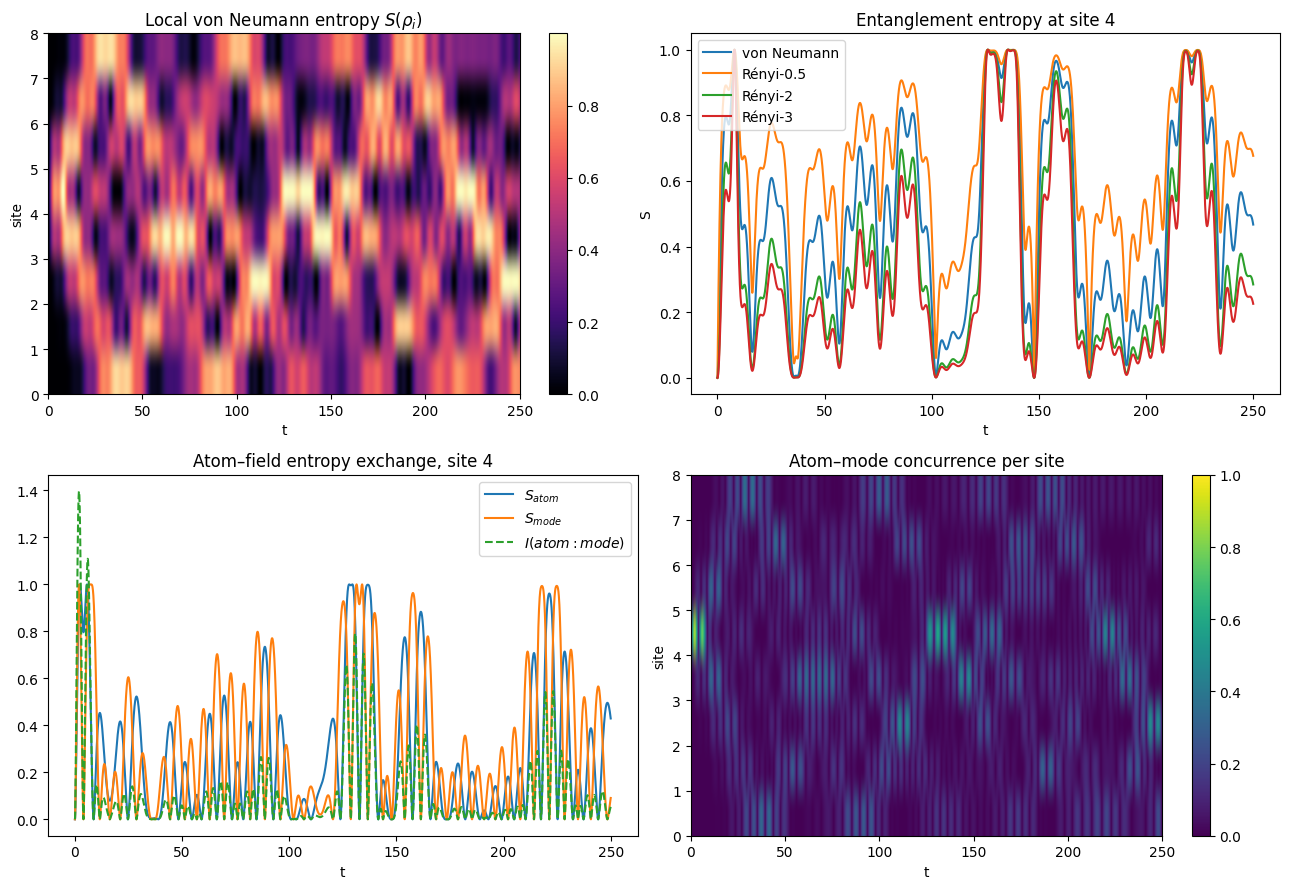

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

im0 = axes[0,0].imshow(S_vn.T, aspect="auto", origin="lower",
                        extent=[time_axis[0], time_axis[-1], 0, N_SITES],
                        cmap="magma")
axes[0,0].set(title="Local von Neumann entropy $S(\\rho_i)$", xlabel="t", ylabel="site")
fig.colorbar(im0, ax=axes[0,0])

axes[0,1].plot(time_axis, S_vn_cut, label="von Neumann")
for a in RENYI_ORDERS:
    axes[0,1].plot(time_axis, S_ren_cut[a], label=f"Rényi-{a}")
axes[0,1].set(title=f"Entanglement entropy at site {ENT_SITE}", xlabel="t", ylabel="S")
axes[0,1].legend()

axes[1,0].plot(time_axis, S_atom[:, ENT_SITE], label="$S_{atom}$")
axes[1,0].plot(time_axis, S_mode[:, ENT_SITE], label="$S_{mode}$")
axes[1,0].plot(time_axis, I_am[:, ENT_SITE], label="$I(atom:mode)$", ls="--")
axes[1,0].set(title=f"Atom–field entropy exchange, site {ENT_SITE}", xlabel="t")
axes[1,0].legend()

im1 = axes[1,1].imshow(C_site.T, aspect="auto", origin="lower",
                        extent=[time_axis[0], time_axis[-1], 0, N_SITES],
                        cmap="viridis", vmin=0, vmax=1)
axes[1,1].set(title="Atom–mode concurrence per site", xlabel="t", ylabel="site")
fig.colorbar(im1, ax=axes[1,1])

plt.tight_layout()
plt.show()